# Extensión UD1 — Centro y dispersión en las latencias

Este notebook amplía el [ejemplo de Anscombe y latencias](UD1_Estadistica_Decisiones_Anscombe_Latencias_Web.ipynb): veremos por qué comunicar solo una media o una mediana puede esconder diferencias importantes.

Trabajaremos primero con las latencias simuladas del ejemplo anterior y después compararemos dos ventanas didácticas de peticiones que tienen **la misma media y la misma mediana**, pero distinta dispersión. Los dos grupos pequeños son datos construidos para aislar la idea; no son mediciones adicionales del servidor.

Ejecuta las celdas en orden. Hace falta tener `latencias_web.csv` en la misma carpeta que este notebook.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

candidatos = [Path.cwd(), Path.cwd() / 'ud01-introduccion-big-data' / '02-ejemplos']
BASE = next((p for p in candidatos if (p / 'latencias_web.csv').is_file()), None)
if BASE is None:
    raise FileNotFoundError('No encuentro latencias_web.csv. Abre el notebook junto al CSV o desde la raíz del repositorio.')

latencias = pd.read_csv(BASE / 'latencias_web.csv')
assert len(latencias) == 1000
assert latencias['duracion_ms'].ge(0).all()
display(latencias.head())

,request_id,instante_peticion,metodo,ruta,estado_http,duracion_ms
0,1,2026-10-15T09:00:00,GET,/inicio,200,1000
1,2,2026-10-15T09:00:01,GET,/inicio,200,1000
2,3,2026-10-15T09:00:02,GET,/inicio,200,100
3,4,2026-10-15T09:00:03,GET,/inicio,200,1000
4,5,2026-10-15T09:00:04,GET,/inicio,200,100


## 1. Recuperamos la distribución original

En el notebook anterior vimos que la media era 280 ms y la mediana 100 ms. Añadamos medidas de dispersión y frecuencias para entender cómo se forma esa media. Recuerda: los datos son sintéticos, con 900 peticiones de 100 ms, 90 de 1.000 ms y 10 de 10.000 ms.

In [2]:
tiempos = latencias['duracion_ms']
resumen = pd.Series({
    'Media (ms)': tiempos.mean(),
    'Mediana (ms)': tiempos.median(),
    'Desviación típica muestral (ms)': tiempos.std(ddof=1),
    'Rango (ms)': tiempos.max() - tiempos.min(),
    'IQR (ms)': tiempos.quantile(0.75) - tiempos.quantile(0.25),
    'P95 (ms)': tiempos.quantile(0.95),
}, name='Valor')
display(resumen.to_frame().round(2))
display(tiempos.value_counts().sort_index().rename_axis('duracion_ms').to_frame('peticiones'))

,Valor
Media (ms),280.00
Mediana (ms),100.00
Desviación típica muestral (ms),1010.75
Rango (ms),9900.00
IQR (ms),0.00
P95 (ms),1000.00


,peticiones
duracion_ms,
100,900
1000,90
10000,10


La media y la mediana describen el centro, pero aquí la desviación típica y el rango revelan que hay una cola de tiempos mucho mayores. Las frecuencias muestran de dónde sale esa dispersión. El siguiente experimento simplifica el problema para comparar dos grupos con exactamente el mismo centro.

## 2. Dos grupos con el mismo centro

Antes de ejecutar la celda, observa los valores y predice qué grupo tendrá mayor desviación típica. ¿Crees que ambos grupos son igual de estables si la media y la mediana coinciden?

In [3]:
estable = np.array([90, 95, 98, 99, 100, 100, 101, 102, 105, 110])
variable = np.array([20, 50, 80, 90, 100, 100, 110, 120, 150, 180])

comparacion = pd.DataFrame({
    'A — más estable': estable,
    'B — más variable': variable,
})
comparacion.index = pd.Index(range(1, 11), name='peticion')
display(comparacion)

,A — más estable,B — más variable
peticion,,
1,90,20
2,95,50
3,98,80
4,99,90
5,100,100
6,100,100
7,101,110
8,102,120
9,105,150


In [4]:
UMBRAL_MS = 110
filas = []
for nombre, valores in comparacion.items():
    s = pd.Series(valores)
    filas.append({
        'Grupo': nombre,
        'Media (ms)': s.mean(),
        'Mediana (ms)': s.median(),
        'Desviación típica muestral (ms)': s.std(ddof=1),
        'Rango (ms)': s.max() - s.min(),
        'IQR (ms)': s.quantile(0.75) - s.quantile(0.25),
        f'Cumplen ≤{UMBRAL_MS} ms (%)': 100 * s.le(UMBRAL_MS).mean(),
    })
resumen_grupos = pd.DataFrame(filas).set_index('Grupo')
display(resumen_grupos.round(2))

assert estable.mean() == variable.mean() == 100
assert np.median(estable) == np.median(variable) == 100
assert np.isclose(estable.std(ddof=1), 5.37, atol=0.01)
assert np.isclose(variable.std(ddof=1), 45.70, atol=0.01)
assert (estable <= UMBRAL_MS).mean() == 1.0
assert (variable <= UMBRAL_MS).mean() == 0.7

,Media (ms),Mediana (ms),Desviación típica muestral (ms),Rango (ms),IQR (ms),Cumplen ≤110 ms (%)
Grupo,,,,,,
A — más estable,100.0,100.0,5.37,20,3.5,100.0
B — más variable,100.0,100.0,45.70,160,35.0,70.0


**Lectura:** media y mediana son 100 ms en ambos grupos, pero B tiene mucha más variabilidad. Con un límite de 110 ms, cumple el 100 % de A y solo el 70 % de B. El centro no describe por sí solo ni la estabilidad del servicio ni el porcentaje que satisface un requisito.

/tmp/ipykernel_36445/3756929459.py:10: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  ejes[1].boxplot([estable, variable], labels=['A — estable', 'B — variable'])


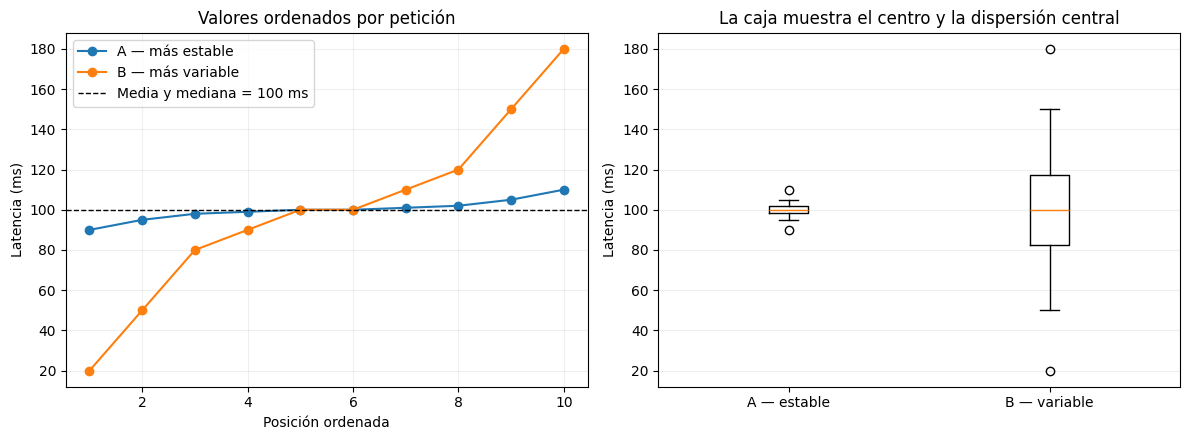

In [5]:
fig, ejes = plt.subplots(1, 2, figsize=(12, 4.5))
indices = np.arange(1, len(estable) + 1)
ejes[0].plot(indices, estable, marker='o', label='A — más estable')
ejes[0].plot(indices, variable, marker='o', label='B — más variable')
ejes[0].axhline(100, color='black', linestyle='--', linewidth=1, label='Media y mediana = 100 ms')
ejes[0].set(title='Valores ordenados por petición', xlabel='Posición ordenada', ylabel='Latencia (ms)')
ejes[0].legend()
ejes[0].grid(alpha=0.2)

ejes[1].boxplot([estable, variable], labels=['A — estable', 'B — variable'])
ejes[1].set(title='La caja muestra el centro y la dispersión central', ylabel='Latencia (ms)')
ejes[1].grid(axis='y', alpha=0.2)
fig.tight_layout()
plt.show()

## 3. Qué medida usar y qué no concluir

- **Media y mediana:** resumen el centro; no indican cuánto se separan los valores entre sí.
- **Desviación típica:** resume la dispersión alrededor de la media y es sensible a valores extremos.
- **Rango:** muestra la distancia entre mínimo y máximo; depende solo de esos dos valores.
- **IQR:** mide la anchura de la mitad central y es más robusto frente a extremos.
- **Proporción bajo un umbral o percentil:** responde a requisitos de servicio como «al menos el 95 % en 500 ms».
- **Gráfico:** permite ver forma, asimetría, grupos y extremos que no quedan descritos por un par de estadísticos.

La dispersión mayor no explica su causa. Para saber por qué hay latencias altas hacen falta otras mediciones (por ejemplo, carga, red o consultas a base de datos). Tampoco se deben borrar valores lentos solo para mejorar un indicador: primero hay que investigar si son errores o sucesos reales.

### Para comprobar que lo entendiste

1. Si dos grupos tienen la misma media y mediana, ¿qué pueden decirte la desviación típica y el IQR que no te dicen esas medidas centrales?
2. ¿Por qué el rango puede cambiar mucho por una sola petición extrema?
3. ¿Qué medida responde al requisito «95 % de peticiones en 500 ms o menos»?
4. ¿Qué gráfico mirarías antes de describir un grupo como «estable»?

**Idea para recordar:** centro + dispersión ofrecen una imagen más completa; centro + dispersión + distribución permiten una lectura aún mejor. Ninguna medida aislada demuestra la causa de lo observado.